# M6 Validation: Embedding Interpolation
End-to-end M6 validation with A4 prompt embedding blending.

In [1]:
from pathlib import Path
import torch
from IPython.display import display
from helpers.methods.navigation import blend_prompt_pair
from helpers.runtime.inference import generate_prompt_baseline, timed_generate_with_embeddings
from helpers.runtime.pipeline import  load_flux_pipeline, resolve_runtime_device
from helpers.runtime.utils import flush_namespace
from helpers.runtime.dtype_handler.parsing import resolve_dtype_for_device

WARNING[XFORMERS]: xFormers can't load C++/CUDA extensions. xFormers was built for:
    PyTorch 2.10.0+cu128 with CUDA 1208 (you have 2.11.0+cu130)
    Python  3.10.11 (you have 3.13.11)
  Please reinstall xformers (see https://github.com/facebookresearch/xformers#installing-xformers)
  Memory-efficient attention, SwiGLU, sparse and more won't be available.
  Set XFORMERS_MORE_DETAILS=1 for more details
W0423 22:57:33.016000 39648 Lib\site-packages\torch\utils\flop_counter.py:29] triton not found; flop counting will not work for triton kernels


Loading pipeline components...:   0%|          | 0/5 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

Error occurred while checking dtype torch.float8_e4m3fn on device cuda: "ufunc_add_CUDA" not implemented for 'Float8_e4m3fn'
Candidate FP8 dtype float8_e4m3fn is not supported on device=cuda
Error occurred while checking dtype torch.float8_e5m2 on device cuda: "ufunc_add_CUDA" not implemented for 'Float8_e5m2'
Candidate FP8 dtype float8_e5m2 is not supported on device=cuda
Falling back from FP8 to torch.float16 on device=cuda; tested candidates=[float8_e4m3fn, float8_e5m2]
Enabled layerwise casting on transformer (storage=torch.float16, compute=torch.bfloat16)
Layerwise casting not enabled; skipping fallback attempt


The module 'Flux2Transformer2DModel' is group offloaded and moving it to cuda via `.to()` is not supported.


Enabled group offloading for text_encoder (offload_type=block_level)
Enabled group offloading for vae (offload_type=leaf_level)
Loaded pipeline with transformer group offload enabled (use_stream=True, low_cpu_mem_usage=False, enable_text_encoder_group_offload=True, enable_vae_group_offload=True)
Enabled VAE slicing via vae.enable_slicing()
Enabled VAE tiling via vae.enable_tiling()
Enabled channels-last memory format on vae
Skipping xFormers attention: No operator found for `memory_efficient_attention_forward` with inputs:
     query       : shape=(1, 2, 1, 40) (torch.float32)
     key         : shape=(1, 2, 1, 40) (torch.float32)
     value       : shape=(1, 2, 1, 40) (torch.float32)
     attn_bias   : <class 'NoneType'>
     p           : 0.0
`fa3F@0.0.0` is not supported because:
    xFormers wasn't build with CUDA support
    requires device with capability >= (8, 0) but your GPU has capability (7, 5) (too old)
    dtype=torch.float32 (supported: {torch.float16, torch.bfloat16})
  

  0%|          | 0/4 [00:00<?, ?it/s]

baseline A in 114.63s -> C:\Users\David\Desktop\thesis\NeLs\project\python\examples\semantic\outputs\m6_embedding_interp_notebook\m6_baseline_prompt_a.png


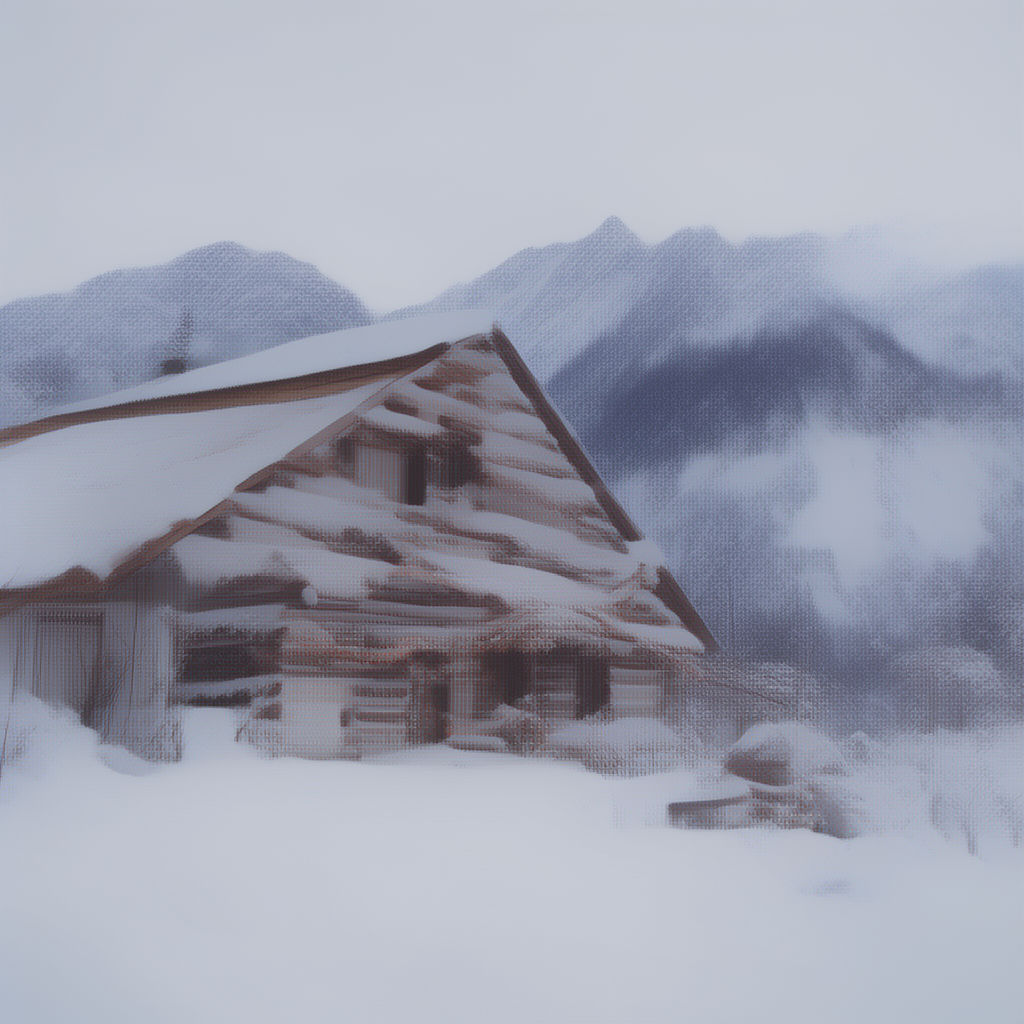

  0%|          | 0/4 [00:00<?, ?it/s]

baseline B in 465.48s -> C:\Users\David\Desktop\thesis\NeLs\project\python\examples\semantic\outputs\m6_embedding_interp_notebook\m6_baseline_prompt_b.png


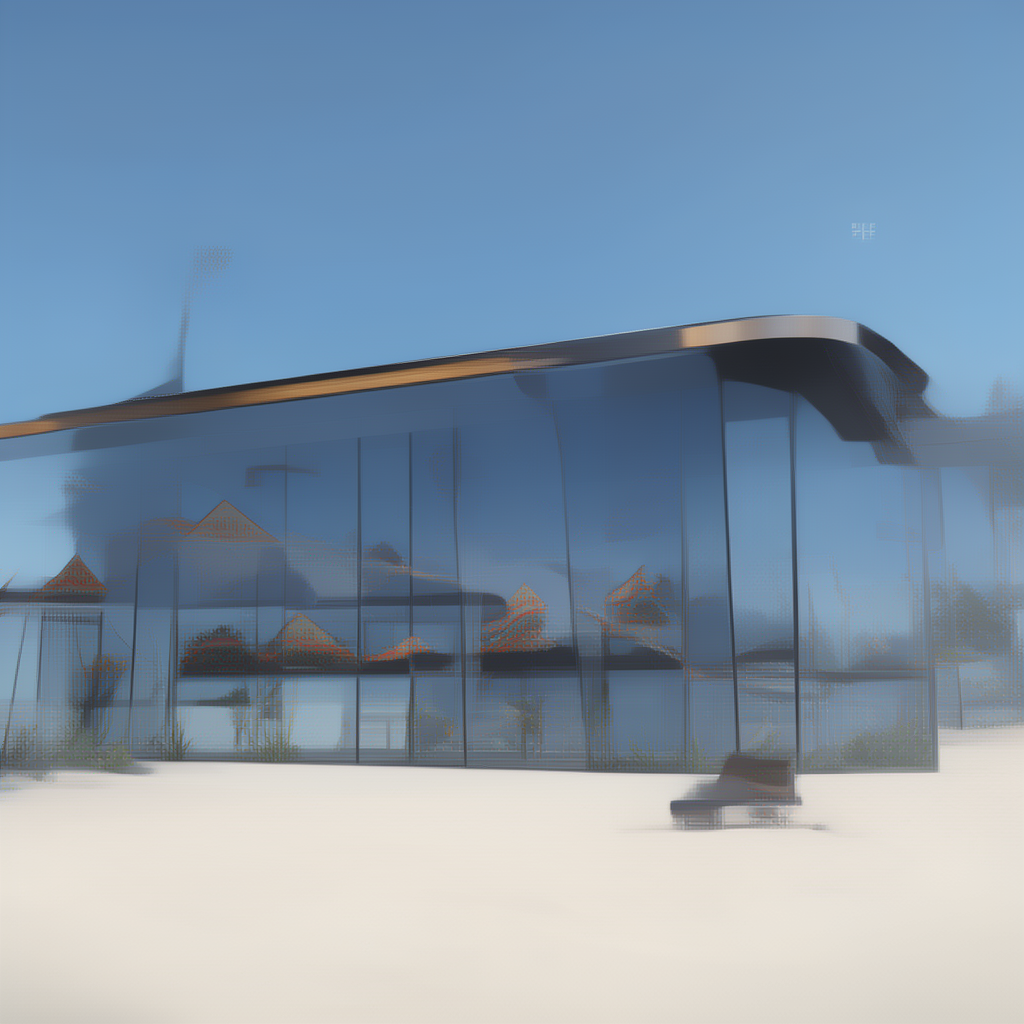

An error occurred: Inference tensors do not track version counter.
Before flush: allocated=7.50 GB, reserved=8.29 GB, peak_allocated=7.79 GB


: 

In [2]:
output_dir = Path('../python/examples/semantic/outputs/m6_embedding_interp_notebook').resolve()
output_dir.mkdir(parents=True, exist_ok=True)

device = resolve_runtime_device()
dtype = resolve_dtype_for_device(device=device)

prompt_a = 'a cozy wooden cabin in snowy mountains'
prompt_b = 'a futuristic glass cabin on a tropical beach'
seed = 808
num_inference_steps = 4
guidance_scale = 0.0
try:
    pipe = load_flux_pipeline(
        torch_dtype=dtype,
        device=device,
        offload_mode="group",
        group_offload_type="leaf_level",
        group_use_stream=True,
        group_low_cpu_mem_usage=False,
        enable_text_encoder_group_offload=True,
        text_encoder_group_offload_type="block_level",
        text_encoder_num_blocks_per_group=1,
        enable_vae_group_offload=True,
        vae_group_offload_type="leaf_level",
        vae_num_blocks_per_group=2,
        enable_vae_slicing=True,
        enable_vae_tiling=True,
        enable_layerwise_casting=True,
        layerwise_storage_dtype=None,  # Auto-select supported FP8 or fallback.
        layerwise_fallback_storage_dtype=torch.float16,
        layerwise_compute_dtype=dtype,
        enable_channels_last=True,
        enable_xformers_attention=True,
        enable_torch_compile=False,
        disable_progress_bar=False
    )

    baseline_a, baseline_a_elapsed, _ = generate_prompt_baseline(
        pipe=pipe,
        prompt=prompt_a,
        seed=seed,
        device=device,
        num_inference_steps=num_inference_steps,
        guidance_scale=guidance_scale,
    )
    baseline_a_path = output_dir / 'm6_baseline_prompt_a.png'
    baseline_a.save(baseline_a_path)
    print(f'baseline A in {baseline_a_elapsed:.2f}s -> {baseline_a_path}')
    display(baseline_a)

    baseline_b, baseline_b_elapsed, _ = generate_prompt_baseline(
        pipe=pipe,
        prompt=prompt_b,
        seed=seed,
        device=device,
        num_inference_steps=num_inference_steps,
        guidance_scale=guidance_scale,
    )
    baseline_b_path = output_dir / 'm6_baseline_prompt_b.png'
    baseline_b.save(baseline_b_path)
    print(f'baseline B in {baseline_b_elapsed:.2f}s -> {baseline_b_path}')
    display(baseline_b)

    for alpha in [0.0, 0.5, 1.0]:
        blended = blend_prompt_pair(
            pipe=pipe,
            prompt_a=prompt_a,
            prompt_b=prompt_b,
            alpha=alpha,
            max_sequence_length=256,
            device=device,
        )

        out, elapsed = timed_generate_with_embeddings(
            pipe=pipe,
            embeddings=blended,
            seed=seed,
            device=device,
            num_inference_steps=num_inference_steps,
            guidance_scale=guidance_scale,
            use_inference_mode=False
        )
        image = out.images[0]

        path = output_dir / f'm6_embed_alpha_{alpha:.2f}.png'
        image.save(path)

        print(f'alpha={alpha:.2f} in {elapsed:.2f}s -> {path} | prompt_embeds_shape={tuple(blended.prompt_embeds.shape)}')
        display(image)
except Exception as e:
    print(f"An error occurred: {e}")
finally:
    flush_namespace(
        globals(),
        "pipe",
        "out",
        "image",
        "baseline_a",
        "baseline_b",
        "blended",
        verbose=True,
        hard_exit=True
    )